<a href="https://colab.research.google.com/github/Bobsilver2003/HrarAI/blob/main/MSc_AI_Lung_Diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- TASK 1: Starting EDA ---


/tmp/ipython-input-4015581720.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='disease_type', data=df, palette='viridis')


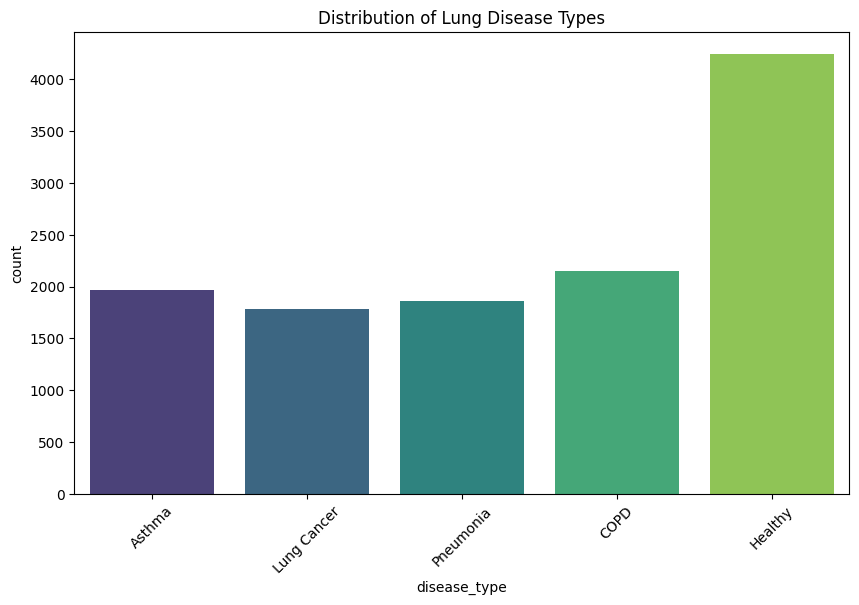


Descriptive Statistics for Key Clinical Features:
                age           bmi    pack_years          spo2  \
count  12000.000000  12000.000000  12000.000000  12000.000000   
mean      58.070833     27.008608     14.767758     95.962800   
std       14.741634      4.961936     14.848183      2.376014   
min       18.000000     16.000000      0.000000     87.200000   
25%       48.000000     23.500000      2.700000     94.400000   
50%       58.000000     27.000000     10.300000     96.000000   
75%       68.000000     30.400000     22.800000     97.700000   
max       90.000000     45.600000     81.800000    100.000000   

       respiratory_rate      crp_mg_L  
count      12000.000000  12000.000000  
mean          17.974033     20.793150  
std            2.993347     30.606319  
min           10.000000      0.000000  
25%           15.900000      1.500000  
50%           18.000000     10.300000  
75%           20.000000     22.900000  
max           28.700000    218.600000  


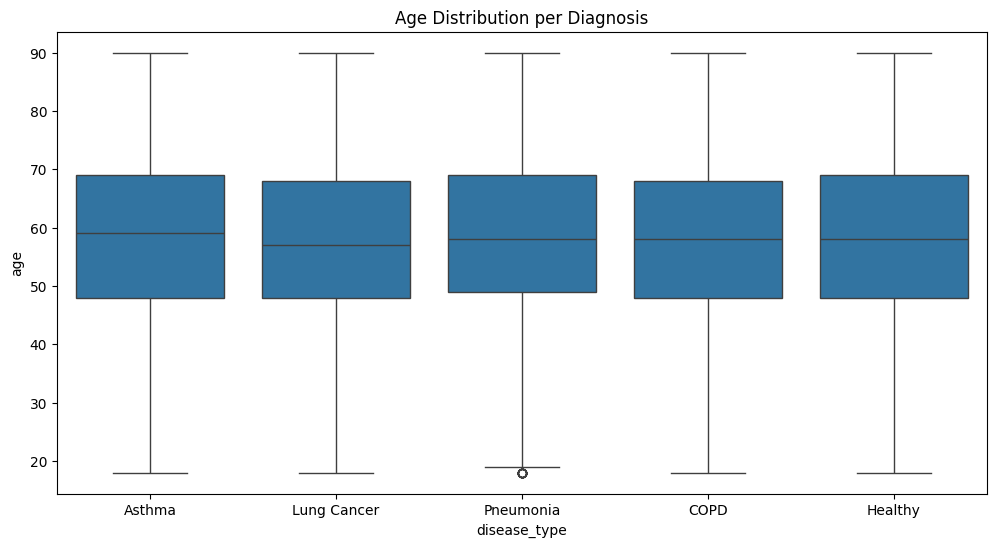

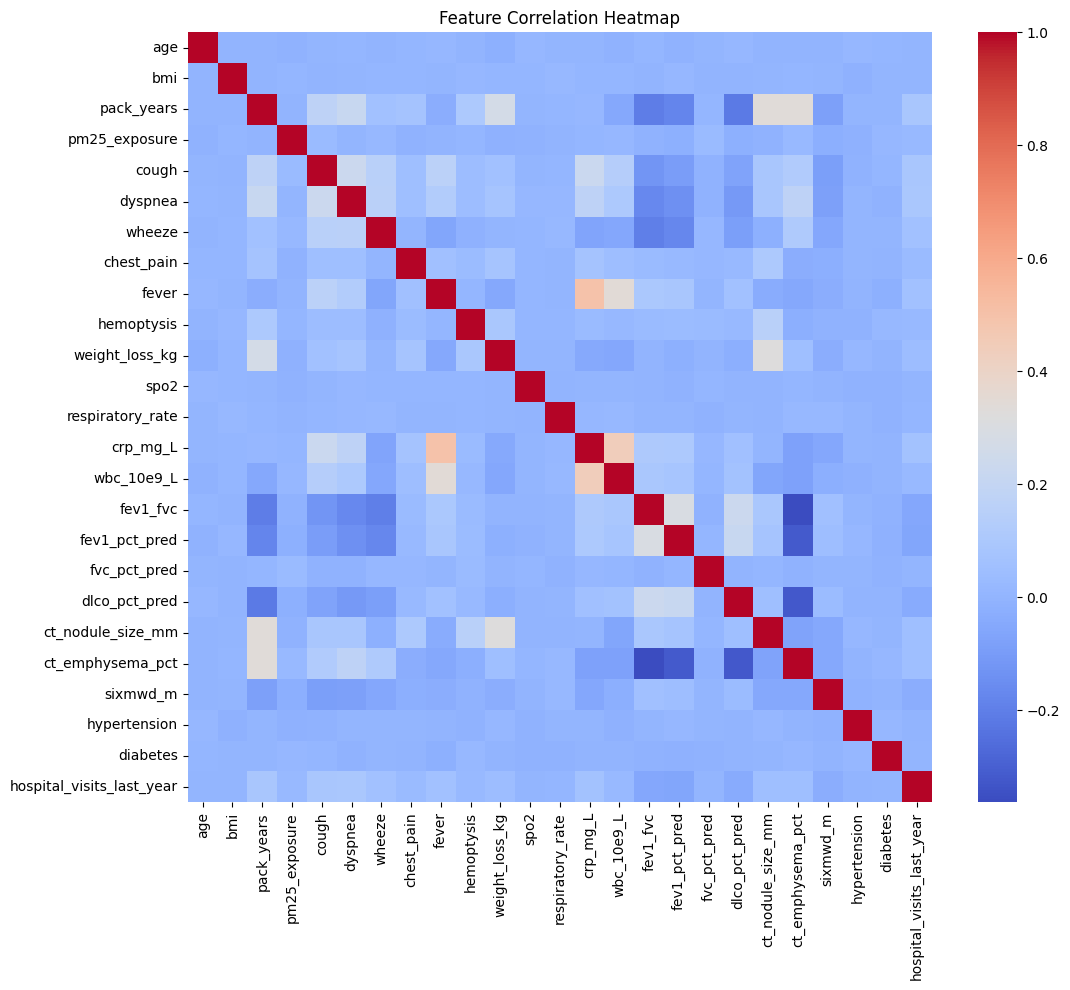

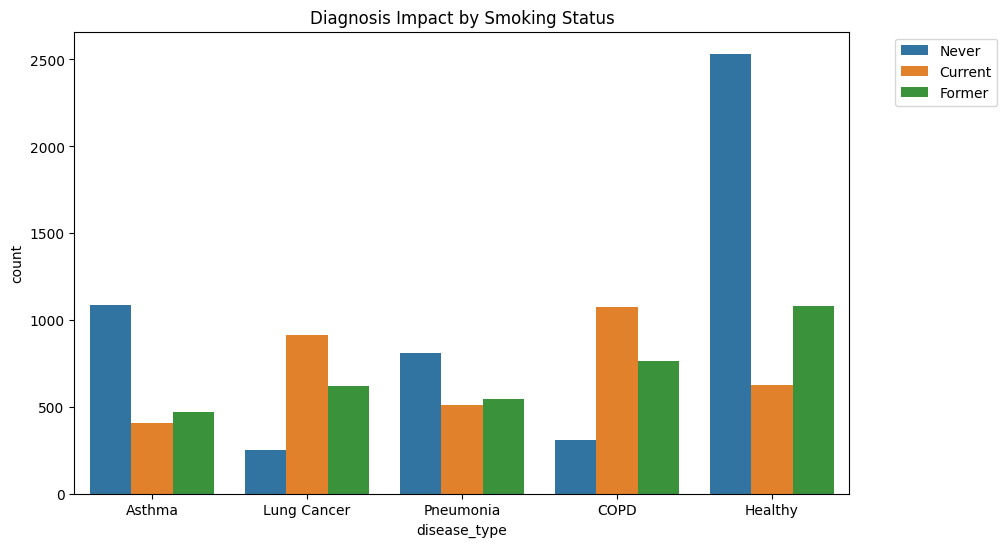


--- TASK 2: Data Preparation ---
Original Data Sample (Before Scaling):
   age   bmi  pack_years
0   49  20.1        21.0
1   61  28.4        34.1
2   70  22.2        15.7
3   47  23.1        49.0
4   70  29.0         6.0

Scaled Data Sample (After Scaling):
        age       bmi  pack_years  pm25_exposure     cough   dyspnea  \
0 -0.615346 -1.392379    0.419748       0.850018  1.181595 -0.811827   
1  0.198709  0.280425    1.302048      -0.644994 -0.846314  1.231790   
2  0.809250 -0.969140    0.062788      -0.465593  1.181595  1.231790   
3 -0.751022 -0.787751    2.305580       0.730417 -0.846314  1.231790   
4  0.809250  0.401350   -0.590518      -1.362600 -0.846314 -0.811827   

     wheeze  chest_pain    fever  hemoptysis  ...  cxr_finding_Hyperinflation  \
0  1.747193   -0.400256 -0.44775   -0.169985  ...                   -0.423784   
1 -0.572346   -0.400256 -0.44775   -0.169985  ...                   -0.423784   
2 -0.572346   -0.400256 -0.44775   -0.169985  ...               

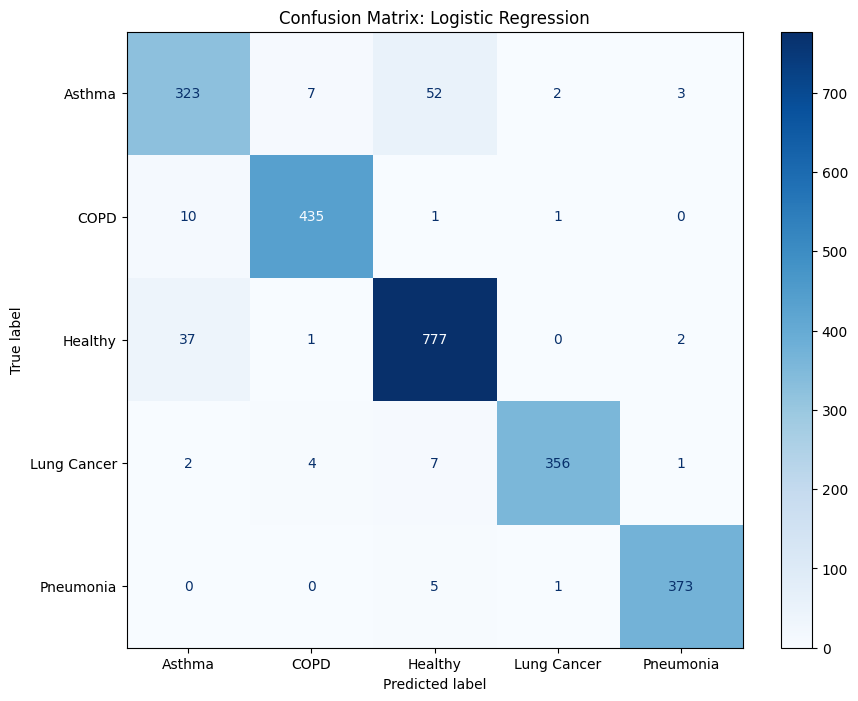

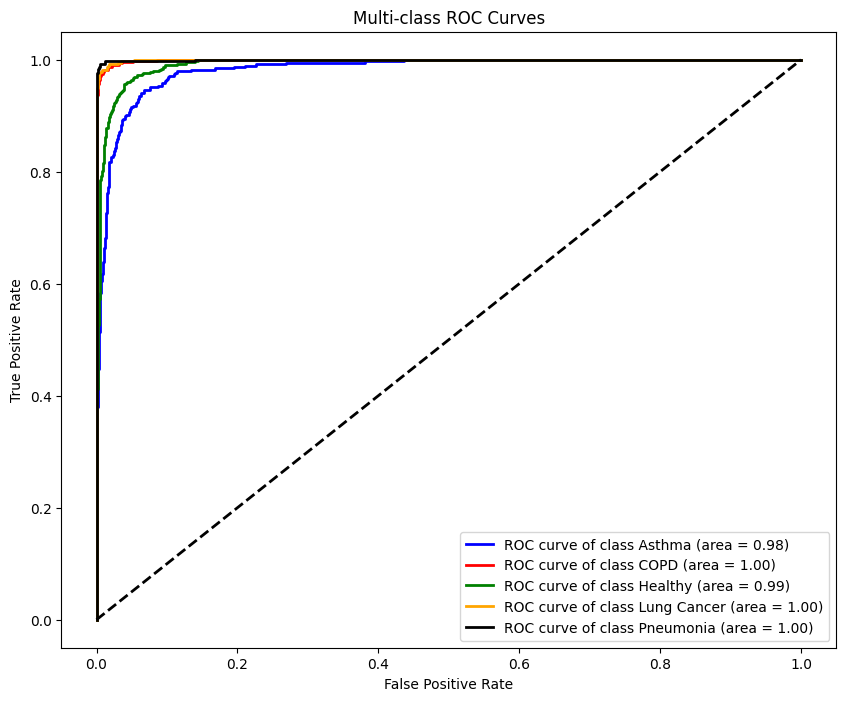


Performing Hyperparameter Tuning on Random Forest...
Best Parameters Found: {'max_depth': None, 'n_estimators': 100}

Generating SHAP Interpretation Plot...


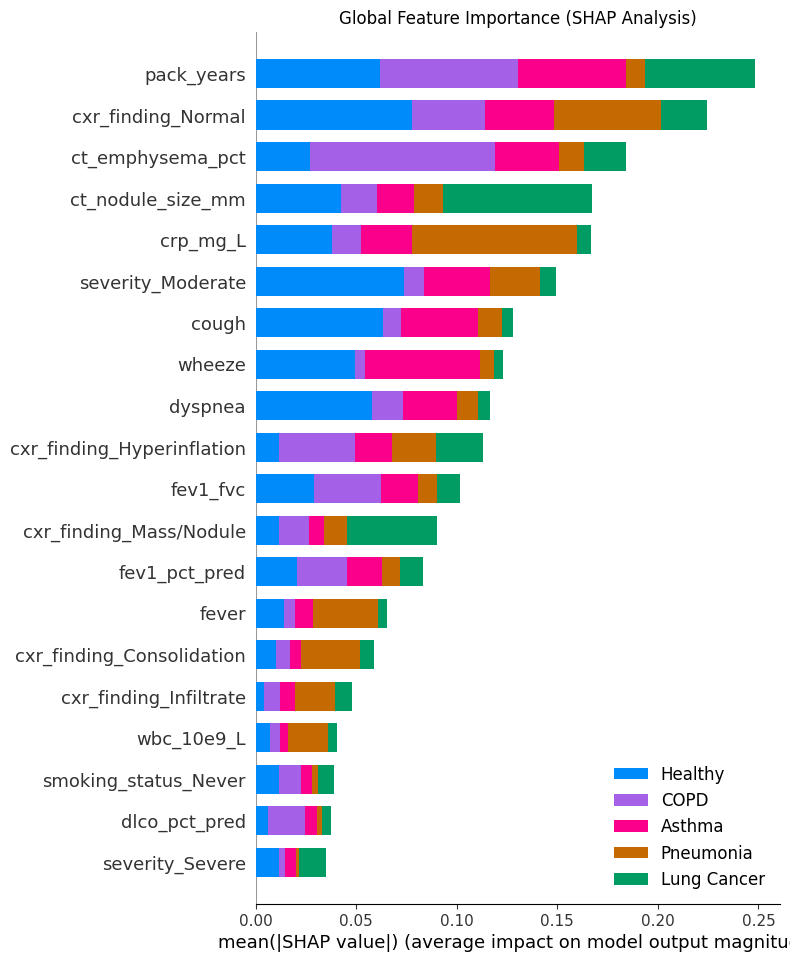


--- Pipeline Complete ---


In [5]:
"""
MSc in Artificial Intelligence - Introduction to AI
Assignment: Leveraging Machine Learning Approaches for Lung Disease Diagnosis
Professor: Dr. Abdelaziz Triki
Student: Ibrahim Al Hussein
Student ID: Q1131323

Description:
This script performs a complete machine learning pipeline including
Exploratory Data Analysis (EDA), Data Preprocessing, Model Training
of five algorithms, Hyperparameter Tuning, and Model Interpretation using SHAP.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize
from itertools import cycle

# ==========================================
# 1. DATA LOADING
# ==========================================
# Load the dataset from the provided public repository
url = "https://raw.githubusercontent.com/abdelDebug/lung_disease/main/lung_disease_v1.csv"
df = pd.read_csv(url)

# ==========================================
# 2. TASK 1: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("--- TASK 1: Starting EDA ---")

# Investigate the distribution of the target variable (Disease Type)
plt.figure(figsize=(10, 6))
sns.countplot(x='disease_type', data=df, palette='viridis')
plt.title('Distribution of Lung Disease Types')
plt.xticks(rotation=45)
plt.show()

# Generate descriptive statistics for numerical clinical features
numerical_features = ['age', 'bmi', 'pack_years', 'spo2', 'respiratory_rate', 'crp_mg_L']
print("\nDescriptive Statistics for Key Clinical Features:")
print(df[numerical_features].describe())

# Visualize Trends: Age distribution across different disease categories
plt.figure(figsize=(12, 6))
sns.boxplot(x='disease_type', y='age', data=df)
plt.title('Age Distribution per Diagnosis')
plt.show()

# Correlation Heatmap to identify links between numerical features
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['patient_id'])
sns.heatmap(numeric_df.corr(), annot=False, cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

# Link between Lifestyle (Smoking) and Diagnosis
plt.figure(figsize=(10, 6))
sns.countplot(x='disease_type', hue='smoking_status', data=df)
plt.title('Diagnosis Impact by Smoking Status')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


# ==========================================
# 3. TASK 2: DATA PREPARATION
# ==========================================
print("\n--- TASK 2: Data Preparation ---")

# Handling Missing Values: Impute 'family_history' with 'Unknown'
# This ensures we preserve the full 12,000 record dataset.
df['family_history'] = df['family_history'].fillna('Unknown')

# Dropping irrelevant identifiers
df_clean = df.drop(columns=['patient_id'])

# Encoding Categorical Variables
# Target: Label Encoding
le = LabelEncoder()
df_clean['disease_type'] = le.fit_transform(df_clean['disease_type'])

# Features: One-Hot Encoding for non-ordinal features (Sex, Smoking, etc.)
categorical_cols = ['sex', 'smoking_status', 'occupation', 'cxr_finding', 'severity', 'family_history']
df_final = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

# Feature Scaling: StandardScaler
# Justification: Mandatory for distance-based models like SVM and KNN.
# We compare a sample 'Before' and 'After' for the report.
print("Original Data Sample (Before Scaling):")
print(df[['age', 'bmi', 'pack_years']].head())

scaler = StandardScaler()
X = df_final.drop(columns=['disease_type'])
y = df_final['disease_type']
X_scaled = scaler.fit_transform(X)

print("\nScaled Data Sample (After Scaling):")
print(pd.DataFrame(X_scaled, columns=X.columns).head())


# ==========================================
# 4. TASK 3: MODEL TRAINING
# ==========================================
print("\n--- TASK 3: Model Training ---")

# Split dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Define at least five classification algorithms
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Support Vector Machine": SVC(probability=True),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier()
}

# Train and record initial hyperparameters for each algorithm
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"\nModel: {name} trained successfully.")
    print(f"Default Hyperparameters: {model.get_params()}")


# ==========================================
# 5. TASK 4: EVALUATION & VISUALIZATION
# ==========================================
print("\n--- TASK 4: Evaluation and Visualization ---")

# A. Performance Table
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1-Score": f1_score(y_test, y_pred, average='weighted')
    })
print("\nPerformance Comparison Table:")
print(pd.DataFrame(results).sort_values(by="F1-Score", ascending=False))

# B. Visual Diagnostics: Confusion Matrix for Best Model (Logistic Regression)
best_model = models["Logistic Regression"]
y_pred_best = best_model.predict(X_test)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best,
                                        display_labels=le.classes_,
                                        cmap='Blues', ax=ax)
plt.title('Confusion Matrix: Logistic Regression')
plt.show()

# C. Visual Diagnostics: ROC Curves (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
y_score = best_model.predict_proba(X_test)
n_classes = 5

plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green', 'orange', 'black'])
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'ROC curve of class {le.classes_[i]} (area = {roc_auc:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curves')
plt.legend(loc="lower right")
plt.show()

# D. Hyperparameter Tuning using GridSearchCV
print("\nPerforming Hyperparameter Tuning on Random Forest...")
param_grid = {'n_estimators': [50, 100], 'max_depth': [None, 10, 20]}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3)
grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_
print(f"Best Parameters Found: {grid_search.best_params_}")

# E. Model Interpretation using SHAP
print("\nGenerating SHAP Interpretation Plot...")
# Convert X_test back to DataFrame for feature names
X_test_df = pd.DataFrame(X_test, columns=X.columns)
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_df.iloc[:100])

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_df.iloc[:100], class_names=le.classes_, plot_type="bar", show=False)
plt.title("Global Feature Importance (SHAP Analysis)")
plt.show()

print("\n--- Pipeline Complete ---")